The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


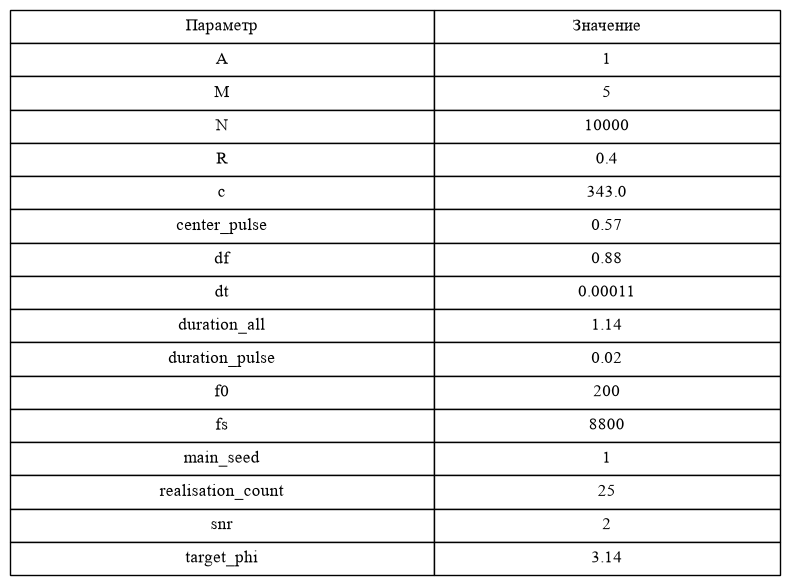

In [28]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.configs.config as cfg
import py_files.configs.comon as comon
import os
from py_files.plot_scrip import create_and_save_table, create_config_table
from py_files.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       calculate_barlet_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       calculate_stiring_matrix, 
                       get_est_phi,
                       calculate_capon_values,
                       calculate_fft, 
                       calculate_f_rms, 
                       filtering_spectrum, 
                       calculate_ifft, 
                       calculate_noise_level, calculate_stiring_vector,
                       calculate_complex_stiring_matrix,calculate_complex_stiring_vector,
                        calculate_full_barlet_values, calculate_full_capon_values
                       )

config_parametrs = cfg.init_rng()
path = "attachment/images/notebook"
os.makedirs(path,exist_ok=True)

create_config_table(config_parametrs)

In [29]:
#sin_signal = get_sin_signal(config_parametrs)
pulse_signal = get_impulse_signal(config_parametrs)
energy_pulse_value = calculate_energy(pulse_signal, config_parametrs["time_vector"])


In [30]:
sin_signal = get_sin_signal(config_parametrs)

pulse_signal = get_impulse_signal(config_parametrs)
pulse_signal_copy = pulse_signal.copy()
energy_pulse_value = calculate_energy(pulse_signal_copy, config_parametrs["time_vector"])

spectrum_signal = calculate_fft(pulse_signal_copy)
f_rms_betta = calculate_f_rms(spectrum_signal, config_parametrs)
en_signal = calculate_energy(pulse_signal, config_parametrs["time_vector"])

K = 0.5
B = K*f_rms_betta
width_rms = K*f_rms_betta
spectrum_filtering_signal = filtering_spectrum(spectrum_signal, B, config_parametrs["fs"])

back_signal = calculate_ifft(spectrum_filtering_signal)
energy_filt_pulse_value = calculate_energy(back_signal, config_parametrs["time_vector"])
f_rms_new = calculate_f_rms(calculate_fft(back_signal),config_parametrs)



In [31]:
tau_array = get_tau_array(config_parametrs)
params_vector_copy = config_parametrs.copy()


In [ ]:
from logging import config


channel_matrix = get_channel_matrix(config_parametrs, tau_array, get_impulse_signal)
W = get_covariation_matrix(channel_matrix, comon.N)
dir_matrix = calculate_stiring_matrix(config_parametrs)
dir_complex_matrix = calculate_complex_stiring_matrix(config_parametrs)



In [33]:
E_bar_true = calculate_full_barlet_values(W,dir_complex_matrix)
E_bar = calculate_barlet_values(W, dir_matrix)
E_cap = calculate_capon_values(W, dir_complex_matrix)
E_cap_true = calculate_full_capon_values(W,dir_complex_matrix)

d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\transforms.py:2914: ComplexWarning: Casting complex values to real discards the imaginary part
  vmin, vmax = map(float, [vmin, vmax])


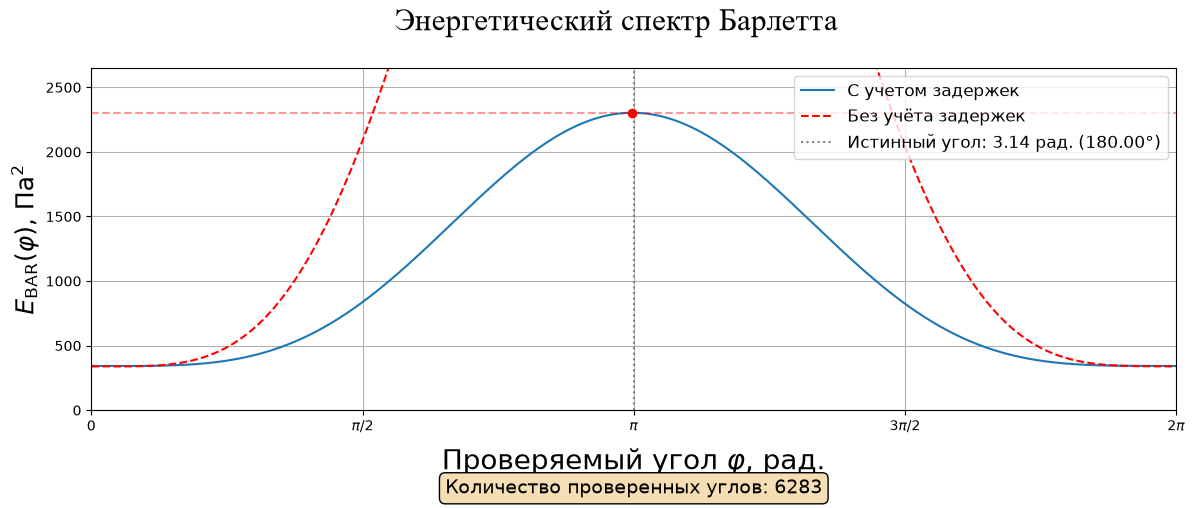

In [34]:
title_main = "Энергетический спектр Барлетта"

snr_ratio = comon.SNR
energy_signal = calculate_energy(pulse_signal,cfg.TIME_VECTOR)
sigma_noise = calculate_noise_level(energy_signal, snr_ratio, comon.DURATION_ALL)
phi_0 = comon.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = comon.A

est_phi = get_est_phi(phi_vector, E_bar_true)
E_max = max(E_bar_true)
snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f}"
)

fig, ax = plt.subplots(figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Бартлетта и отметки углов
ax.plot(
    phi_vector, E_bar_true,
    label=r"C учетом задержек"
)
ax.plot(
    phi_vector, E_bar,
    linestyle = "--",
    color = "red",
    label = "Без учёта задержек"
)
ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.2f} рад. ({np.degrees(phi_0):.2f}°)"
)


ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\transforms.py:2914: ComplexWarning: Casting complex values to real discards the imaginary part
  vmin, vmax = map(float, [vmin, vmax])


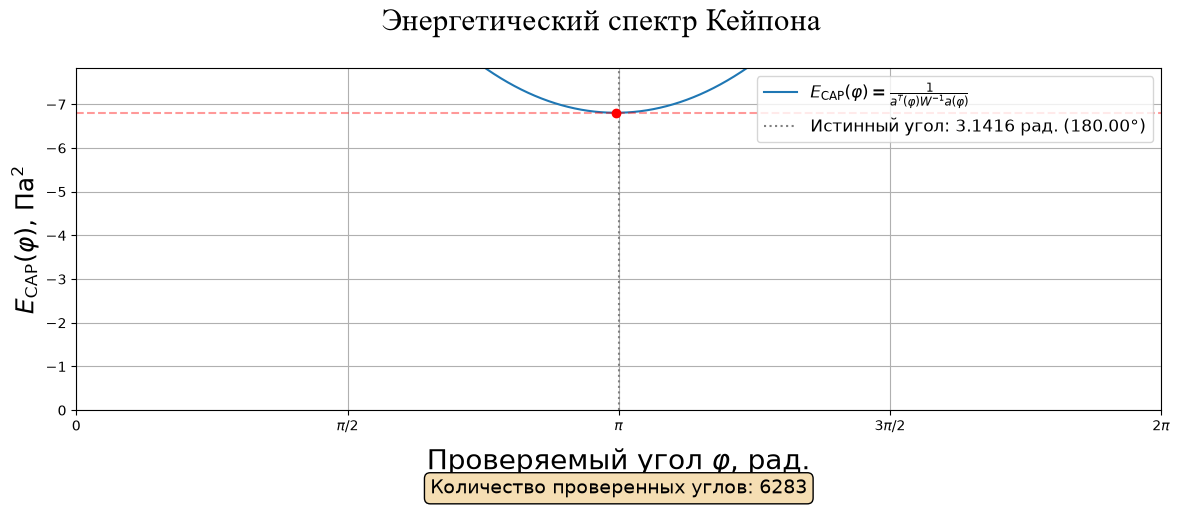

In [35]:
title_main = "Энергетический спектр Кейпона"
snr_ratio = comon.SNR
energy_signal = calculate_energy(pulse_signal,cfg.TIME_VECTOR)
sigma_noise = calculate_noise_level(energy_signal, snr_ratio, comon.DURATION_ALL)
phi_0 = comon.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = comon.A

est_phi = get_est_phi(phi_vector, E_cap)
E_max = max(E_cap)


snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} "
)

fig, ax = plt.subplots(figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Кейпона и отметки углов
ax.plot(
    phi_vector, E_cap,
    label=r"$E_{\mathrm{CAP}}(\varphi)=\frac{1}{a^T(\varphi)W^{-1}a(\varphi)}$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.4f} рад. ({np.degrees(phi_0):.2f}°)"
)


ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    "Энергетический спектр Кейпона",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{CAP}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()